**Перед выполнением ячеек переключесь на среду с графическим процессором.**

> **Выполнил:** Подольский Филипп, магистратура ПМИ, ФМИ ПГНИУ.
>
> Тетрадка выполнена с исходными данными, моделью и параметрами преподавателя: MNIST (все изображения цифр 0 и 1
> из обучающей и тестовой частей), вход 224×224, предобученная **ResNet-18 из torchvision** (`ResNet18_Weights.DEFAULT`,
> ImageNet), по 5 эпох на этап (feature extractor, fine-tuning, обучение с нуля), батч 32.
>
> Выполнено: все этапы тетрадки и графики, «TODO для опытных» (отбор классов до применения преобразований), задача
> с отдельной скоростью обучения для `layer4.1` и **задача с более сложным набором — CIFAR-100** (100 классов, весь набор: 50 000 обучающих и 10 000 тестовых
> изображений), на котором стратегии сравниваются в тех же условиях (раздел 12).
>
> Технические изменения: устройство выбирается в первой ячейке кода (cuda → mps → cpu); `num_workers=0` в
> `DataLoader` (надёжнее на macOS при неинтерактивном запуске); прогресс-бары `tqdm` отключены, чтобы не засорять
> сохранённую тетрадку; к функции обучения добавлен замер времени.

In [1]:
%matplotlib inline
# ── Настройки запуска (добавлено при выполнении работы) ──────────────────────────────────────────
# Устройство: cuda -> mps -> cpu. Режим быстрой проверки NN_SMOKE=1: крошечные подвыборки и 1 эпоха
# (в обычном запуске — параметры из задания). Данные и кэши моделей — в папке ../data.
import os
os.environ.setdefault('PYTORCH_ENABLE_MPS_FALLBACK', '1')   # операции, которых нет в MPS, выполняются на CPU
SMOKE = os.environ.get('NN_SMOKE') == '1'
DATA = '../data'
os.makedirs(DATA, exist_ok=True)
os.environ.setdefault('TORCH_HOME', os.path.abspath(os.path.join(DATA, 'torch_cache')))   # веса torchvision
os.environ.setdefault('HF_HOME', os.path.abspath(os.path.join(DATA, 'hf_cache')))         # модели и датасеты HuggingFace

import torch

def get_device():
    """cuda -> mps -> cpu; переменной окружения NN_DEVICE устройство можно задать явно (например, NN_DEVICE=cpu)."""
    if os.environ.get('NN_DEVICE'):
        return torch.device(os.environ['NN_DEVICE'])
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')

def S(full, smoke):
    """Параметр запуска: значение из задания (full) или уменьшенное для проверки NN_SMOKE=1 (smoke)."""
    return smoke if SMOKE else full

device = get_device()
print(f'Устройство: {device} | режим: {"быстрая проверка (NN_SMOKE=1)" if SMOKE else "полный запуск"}')

Устройство: mps | режим: полный запуск


# 🧪 Практическое занятие: Transfer Learning (дообучение нейросети) на классах, отсутствующих в ImageNet

**Цель работы:** Научиться применять Transfer Learning для решения задачи классификации изображений с использованием предобученной модели. Мы загрузим модель ResNet-18, обученную на ImageNet, и дообучим (fine-tune) её для классификации двух классов из датасета **MNIST**: цифры **0** и **1**. Эти классы **отсутствуют в ImageNet**, что позволит наглядно продемонстрировать эффективность переноса признаков даже на совершенно новые данные.

**План:**
1. Загрузка и подготовка данных (MNIST, только цифры 0 и 1)
2. Преобразование одноканальных изображений в трёхканальные для подачи в ResNet
3. Загрузка предобученной модели и замена последнего слоя
4. Обучение только нового классификатора (feature extractor)
5. Дообучение всей сети (fine-tuning) с уменьшенной скоростью обучения
6. Сравнение результатов с обучением с нуля
7. Визуализация результатов и выводы

**Задача**: в примерах ниже точность почти сразу становится равной 1. Попробовать либо доавить все цифры, не только 0 и 1, либо взять вообще какой-нибудь более сложный набор данных.

## 1. Импортируем необходимые библиотеки

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
import torchvision
from torchvision import datasets, transforms, models
import matplotlib.pyplot as plt
import numpy as np
import copy
import os
import random
import time


# Прогресс-бары отключены (в сохранённой тетрадке они превращаются в сотни строк)
def tqdm(iterable, **kwargs):
    return iterable

# Установка seed для воспроизводимости
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

# Определяем устройство
device = get_device()
print(f'Используется устройство: {device}')

Используется устройство: mps


## 2. Подготовка данных

Мы используем датасет MNIST, но оставим только два класса: цифры **0** и **1**. Для подачи в ResNet, который ожидает трёхканальные изображения размером 224×224, мы преобразуем одноканальные изображения в трёхканальные путём копирования канала и применим ресайз.

In [3]:
# Определяем трансформации для train и val
train_transform = transforms.Compose([
    transforms.Resize(224),                     # увеличиваем до 224x224
    transforms.Grayscale(num_output_channels=3),# конвертируем 1 канал в 3 (повторяем)
    transforms.RandomHorizontalFlip(),          # аугментация: случайное отражение (для цифр может быть неестественно, но оставим)
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_transform = transforms.Compose([
    transforms.Resize(224),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Загружаем MNIST
train_full = datasets.MNIST(root=DATA, train=True, download=True, transform=train_transform)
test_full = datasets.MNIST(root=DATA, train=False, download=True, transform=val_transform)

# Индексы классов: 0 и 1.
# TODO для опытных (см. ниже): классы отбираем по массиву меток targets, не применяя преобразования к картинкам
selected_classes = [0, 1]
train_indices = [i for i, label in enumerate(train_full.targets.tolist()) if label in selected_classes]
test_indices = [i for i, label in enumerate(test_full.targets.tolist()) if label in selected_classes]
if SMOKE:                                       # только быстрая проверка: крошечные подвыборки
    train_indices, test_indices = train_indices[:64], test_indices[:64]

# Создаём подмножества
train_dataset = Subset(train_full, train_indices)
test_dataset = Subset(test_full, test_indices)

# Преобразуем метки: 0→0, 1→1 (они и так 0 и 1)
# Но можно оставить как есть, поскольку Subset сохраняет исходные метки.

# Создаём загрузчики (num_workers=0: на macOS при неинтерактивном запуске так надёжнее)
batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=0)

print(f'Размер обучающей выборки (0 и 1): {len(train_dataset)}')
print(f'Размер тестовой выборки (0 и 1): {len(test_dataset)}')
print('Баланс классов в обучении:', np.bincount(train_full.targets[train_indices].numpy()).tolist())

Размер обучающей выборки (0 и 1): 12665
Размер тестовой выборки (0 и 1): 2115
Баланс классов в обучении: [5923, 6742]


**TODO для опытных**: Изменить порядок обработки так, чтобы графические преобразования не применялись к цифрам 2,3,4... (только к 0 и 1).

In [4]:
# TODO для опытных. В исходной ячейке индексы отбирались так:
#     [i for i, (_, label) in enumerate(train_full) if label in selected_classes]
# Обращение train_full[i] каждый раз применяет ВЕСЬ transform (Resize до 224, Grayscale->RGB, ToTensor, Normalize)
# к каждому изображению всех 10 классов, хотя нужны только метки. Правильный порядок: сначала отобрать
# индексы по меткам (train_full.targets), а преобразования применять только к отобранным 0 и 1 — при обучении.
# Сравним время двух способов на тестовой части MNIST:
probe = test_full if not SMOKE else Subset(test_full, range(300))
t0 = time.perf_counter()
old_way = [i for i, (_, label) in enumerate(probe) if label in selected_classes]
t_old = time.perf_counter() - t0

t0 = time.perf_counter()
new_way = [i for i, label in enumerate(test_full.targets[:len(probe)].tolist()) if label in selected_classes]
t_new = time.perf_counter() - t0

print(f'изображений: {len(probe)}')
print(f'старый способ (с преобразованием всех картинок): {t_old:.2f} с')
print(f'новый способ (только по меткам):                 {t_new * 1000:.1f} мс  -> быстрее в {t_old / t_new:.0f} раз')
print('индексы совпадают:', old_way == new_way)

изображений: 10000
старый способ (с преобразованием всех картинок): 5.00 с
новый способ (только по меткам):                 0.4 мс  -> быстрее в 11264 раз
индексы совпадают: True


## 3. Загрузка предобученной модели и замена последнего слоя

Загрузим ResNet-18 с весами ImageNet. Заменим последний полносвязный слой (`model.fc`) на новый, соответствующий нашей задаче (2 класса).

In [5]:
from torchvision.models.resnet import ResNet18_Weights
# Загружаем предобученный ResNet-18
model = models.resnet18(weights=ResNet18_Weights.DEFAULT)

# Замораживаем все слои (для начала будем обучать только последний)
for param in model.parameters():
    param.requires_grad = False

# Получаем размер входа последнего слоя
num_features = model.fc.in_features
# Создаём новый классификатор
model.fc = nn.Linear(num_features, 2)

model = model.to(device)

# Выведем структуру модели (последние слои)
print(model)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

## 4. Функции для обучения и оценки

In [6]:
def train_epoch(model, loader, criterion, optimizer):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for inputs, labels in tqdm(loader, desc='Обучение', leave=False):
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        _, preds = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (preds == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc

def evaluate(model, loader, criterion):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in tqdm(loader, desc='Оценка', leave=False):
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (preds == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc

def train_model(model, train_loader, test_loader, criterion, optimizer, epochs, scheduler=None):
    history = {'train_loss': [], 'train_acc': [], 'test_loss': [], 'test_acc': []}
    best_acc = 0.0
    best_weights = copy.deepcopy(model.state_dict())

    t0 = time.perf_counter()
    for epoch in range(1, epochs+1):
        print(f'\nЭпоха {epoch}/{epochs}')
        train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer)
        test_loss, test_acc = evaluate(model, test_loader, criterion)

        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['test_loss'].append(test_loss)
        history['test_acc'].append(test_acc)

        print(f'Train Loss: {train_loss:.4f} Acc: {train_acc:.4f}')
        print(f'Test Loss: {test_loss:.4f} Acc: {test_acc:.4f}')

        if scheduler:
            scheduler.step()

        # Сохраняем лучшую модель
        if test_acc > best_acc:
            best_acc = test_acc
            best_weights = copy.deepcopy(model.state_dict())

    history['time'] = time.perf_counter() - t0
    print(f'\nЛучшая точность на тесте: {best_acc:.4f}  (время {history["time"]:.0f} с)')
    model.load_state_dict(best_weights)
    return model, history

## 5. Этап 1: Обучение только нового классификатора (Feature Extractor)

Сначала обучим только последний слой, оставив остальные замороженными. Это позволит быстро получить базовое качество и проверить, насколько хорошо предобученные признаки (из ImageNet) подходят для распознавания рукописных цифр.

In [7]:
criterion = nn.CrossEntropyLoss()
optimizer_fe = optim.Adam(model.fc.parameters(), lr=1e-3)

# Замораживаем все слои
for param in model.parameters():
    param.requires_grad = False

# Размораживаем только последний слой (классификатор)
for param in model.fc.parameters():
    param.requires_grad = True

model_fe, history_fe = train_model(model, train_loader, test_loader, criterion, optimizer_fe, epochs=S(5, 1))


Эпоха 1/5


Train Loss: 0.0506 Acc: 0.9878
Test Loss: 0.0127 Acc: 0.9972

Эпоха 2/5


Train Loss: 0.0134 Acc: 0.9968
Test Loss: 0.0062 Acc: 0.9986

Эпоха 3/5


Train Loss: 0.0097 Acc: 0.9972
Test Loss: 0.0038 Acc: 0.9995

Эпоха 4/5


Train Loss: 0.0082 Acc: 0.9976
Test Loss: 0.0039 Acc: 0.9995

Эпоха 5/5


Train Loss: 0.0073 Acc: 0.9972
Test Loss: 0.0024 Acc: 0.9995

Лучшая точность на тесте: 0.9995  (время 107 с)


## 6. Этап 2: Дообучение всей сети (Fine-Tuning)

Теперь разморозим все слои и продолжим обучение с маленькой скоростью обучения, чтобы аккуратно подстроить веса под новые данные (цифры).

In [8]:
# Размораживаем все слои
for param in model.parameters():
    param.requires_grad = True

# Параметры всех слоёв кроме того, который называется "fc" (последний)
base_params = [p for name, p in model.named_parameters() if 'fc' not in name]

# Используем маленькую скорость обучения для предобученных слоёв
optimizer_ft = optim.Adam([
    {'params': base_params, 'lr': 1e-5},                # маленькая для ранних слоёв
    {'params': model.fc.parameters(), 'lr': 1e-3}       # большая для классификатора
])

# Планировщик делает разную скорость для разных эпох, это к Fine-Tuning отношения не имеет.
# Добавим scheduler для плавного уменьшения LR
# step_size - количество эпох внутри одного этапа обучения.
# gamma - множитель изменения скорости обучения между этапами обучения.
# scheduler = optim.lr_scheduler.StepLR(optimizer_ft, step_size=3, gamma=0.1)

model_ft, history_ft = train_model(model, train_loader, test_loader, criterion, optimizer_ft, epochs=S(5, 1))


Эпоха 1/5


Train Loss: 0.0042 Acc: 0.9987
Test Loss: 0.0000 Acc: 1.0000

Эпоха 2/5


Train Loss: 0.0007 Acc: 0.9998
Test Loss: 0.0001 Acc: 1.0000

Эпоха 3/5


Train Loss: 0.0014 Acc: 0.9996
Test Loss: 0.0001 Acc: 1.0000

Эпоха 4/5


Train Loss: 0.0007 Acc: 0.9997
Test Loss: 0.0000 Acc: 1.0000

Эпоха 5/5


Train Loss: 0.0001 Acc: 1.0000
Test Loss: 0.0000 Acc: 1.0000

Лучшая точность на тесте: 1.0000  (время 214 с)


**Задача**: спросить у LLM, как задать индивидуальную скорость обучения для layer4.1.BasicBlock, который идёт последним перед avgpool и fc, попробовать обучить сеть, сравнить результаты.

In [9]:
# Отдельная скорость обучения для layer4.1 (последний BasicBlock перед avgpool и fc): группы параметров оптимизатора.
# У каждой группы свой lr; параметры отбираем по именам из model.named_parameters().
def layerwise_optimizer(model, lr_base=1e-5, lr_layer41=1e-4, lr_fc=1e-3):
    groups = {'base': [], 'layer4.1': [], 'fc': []}
    for name, p in model.named_parameters():
        p.requires_grad = True
        key = 'fc' if name.startswith('fc.') else 'layer4.1' if name.startswith('layer4.1.') else 'base'
        groups[key].append(p)
    return optim.Adam([
        {'params': groups['base'], 'lr': lr_base},          # ранние слои почти не трогаем
        {'params': groups['layer4.1'], 'lr': lr_layer41},   # последний блок адаптируем активнее
        {'params': groups['fc'], 'lr': lr_fc},              # новый классификатор учим быстро
    ])

opt_demo = layerwise_optimizer(copy.deepcopy(model))
for g, name in zip(opt_demo.param_groups, ['base', 'layer4.1', 'fc']):
    print(f'{name:9s} lr = {g["lr"]:.0e}, параметров: {sum(p.numel() for p in g["params"]):,}')
print('Имена параметров layer4.1:', [n for n, _ in model.named_parameters() if n.startswith('layer4.1.')])

base      lr = 1e-05, параметров: 6,455,872
layer4.1  lr = 1e-04, параметров: 4,720,640
fc        lr = 1e-03, параметров: 1,026
Имена параметров layer4.1: ['layer4.1.conv1.weight', 'layer4.1.bn1.weight', 'layer4.1.bn1.bias', 'layer4.1.conv2.weight', 'layer4.1.bn2.weight', 'layer4.1.bn2.bias']


Как отмечено в задании, на цифрах 0 и 1 точность почти сразу становится равной 1, поэтому сравнение с отдельной скоростью обучения для `layer4.1` выполнено на более сложном наборе CIFAR-100 — в разделе 12 вместе с остальными стратегиями.

## 7. Сравнение результатов: Feature Extractor vs Fine-Tuning

Построим графики потерь и точности для обеих стратегий.

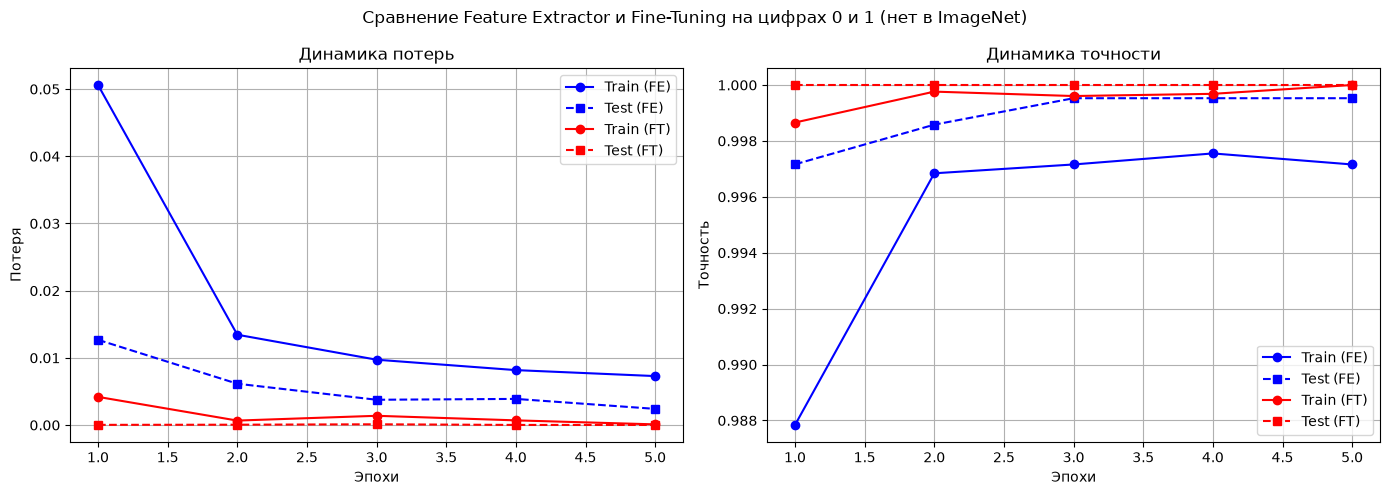

Лучшая точность Feature Extractor: 0.9995
Лучшая точность Fine-Tuning: 1.0000


In [10]:
def plot_history(hist_fe, hist_ft, title):
    epochs_fe = range(1, len(hist_fe['train_loss'])+1)
    epochs_ft = range(1, len(hist_ft['train_loss'])+1)

    plt.figure(figsize=(14,5))

    plt.subplot(1,2,1)
    plt.plot(epochs_fe, hist_fe['train_loss'], 'b-o', label='Train (FE)')
    plt.plot(epochs_fe, hist_fe['test_loss'], 'b--s', label='Test (FE)')
    plt.plot(epochs_ft, hist_ft['train_loss'], 'r-o', label='Train (FT)')
    plt.plot(epochs_ft, hist_ft['test_loss'], 'r--s', label='Test (FT)')
    plt.xlabel('Эпохи')
    plt.ylabel('Потеря')
    plt.title('Динамика потерь')
    plt.legend()
    plt.grid(True)

    plt.subplot(1,2,2)
    plt.plot(epochs_fe, hist_fe['train_acc'], 'b-o', label='Train (FE)')
    plt.plot(epochs_fe, hist_fe['test_acc'], 'b--s', label='Test (FE)')
    plt.plot(epochs_ft, hist_ft['train_acc'], 'r-o', label='Train (FT)')
    plt.plot(epochs_ft, hist_ft['test_acc'], 'r--s', label='Test (FT)')
    plt.xlabel('Эпохи')
    plt.ylabel('Точность')
    plt.title('Динамика точности')
    plt.legend()
    plt.grid(True)

    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

plot_history(history_fe, history_ft, 'Сравнение Feature Extractor и Fine-Tuning на цифрах 0 и 1 (нет в ImageNet)')

print(f"Лучшая точность Feature Extractor: {max(history_fe['test_acc']):.4f}")
print(f"Лучшая точность Fine-Tuning: {max(history_ft['test_acc']):.4f}")

## 8. Визуализация предсказаний на тестовых изображениях

Посмотрим, как наша дообученная модель справляется с реальными картинками цифр 0 и 1.

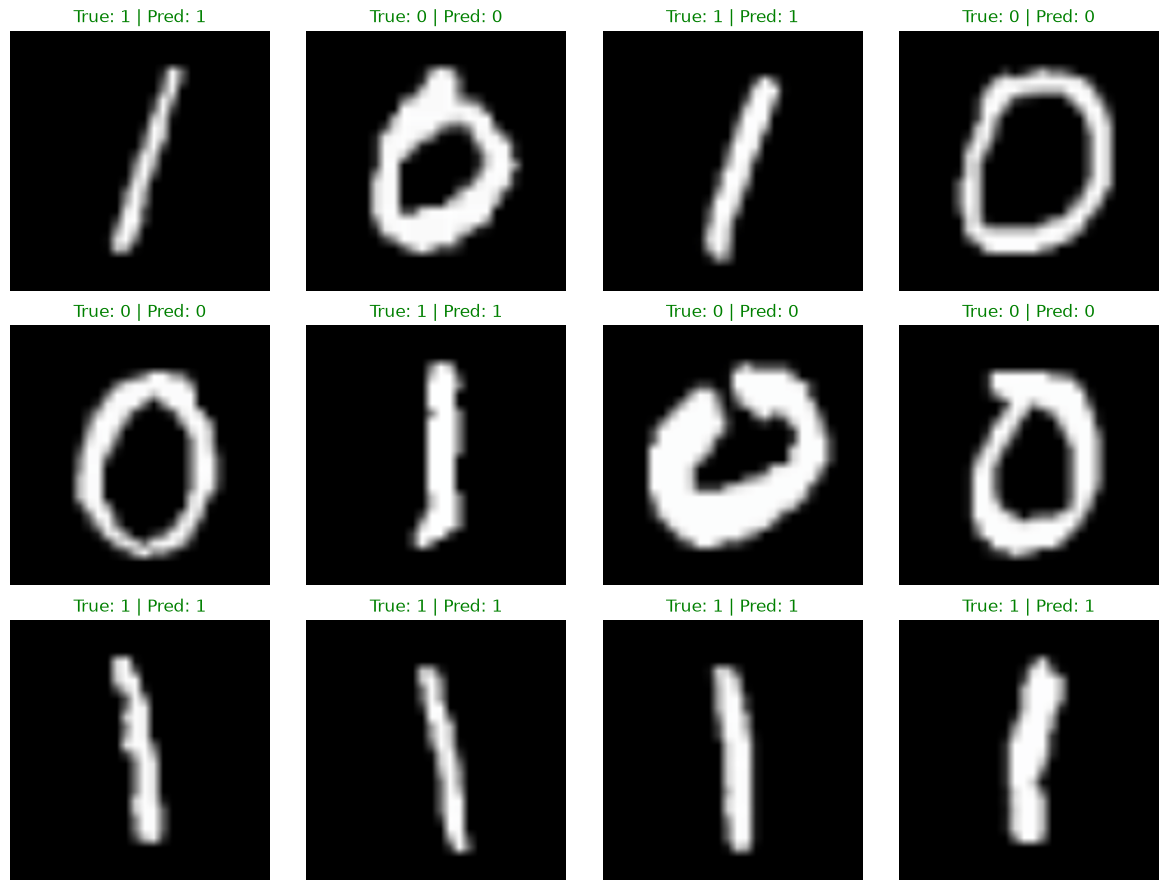

In [11]:
# Определим средние и стандартные отклонения для нормализации ImageNet
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

dataiter = iter(test_loader)
images, labels = next(dataiter)
images, labels = images.to(device), labels.to(device)

model_ft.eval()
with torch.no_grad():
    outputs = model_ft(images)
    _, preds = torch.max(outputs, 1)

fig, axes = plt.subplots(3, 4, figsize=(12,9))
for idx, ax in enumerate(axes.flat):
    if idx >= len(images):
        break
    img = images[idx].cpu()
    label = labels[idx].item()
    pred = preds[idx].item()
    title = f'True: {label} | Pred: {pred}'

    # Преобразуем тензор (C, H, W) в (H, W, C) для отображения
    img_disp = img.numpy().transpose((1, 2, 0))
    # Денормализация: было (x - mean)/std -> обратно x = img_disp * std + mean
    img_disp = std * img_disp + mean
    img_disp = np.clip(img_disp, 0, 1)  # обрезаем значения за пределами [0,1]

    ax.imshow(img_disp)
    ax.set_title(title, color='green' if label == pred else 'red')
    ax.axis('off')

plt.tight_layout()
plt.show()

## 9. Дополнительно: обучение модели с нуля для сравнения

Чтобы убедиться в эффективности Transfer Learning, обучим такую же архитектуру ResNet-18, но со случайной инициализацией, на нашем подмножестве MNIST (цифры 0 и 1).

In [12]:
model_scratch = models.resnet18(weights=None, num_classes=2).to(device)
optimizer_scratch = optim.Adam(model_scratch.parameters(), lr=1e-3)
scheduler_scratch = optim.lr_scheduler.StepLR(optimizer_scratch, step_size=7, gamma=0.1)

model_scratch, history_scratch = train_model(model_scratch, train_loader, test_loader, criterion, optimizer_scratch, epochs=S(5, 1), scheduler=scheduler_scratch)

print(f"Лучшая точность обучения с нуля: {max(history_scratch['test_acc']):.4f}")


Эпоха 1/5


Train Loss: 0.0226 Acc: 0.9939
Test Loss: 0.0139 Acc: 0.9967

Эпоха 2/5


Train Loss: 0.0103 Acc: 0.9967
Test Loss: 0.0013 Acc: 0.9995

Эпоха 3/5


Train Loss: 0.0075 Acc: 0.9978
Test Loss: 0.0060 Acc: 0.9986

Эпоха 4/5


Train Loss: 0.0066 Acc: 0.9984
Test Loss: 0.0014 Acc: 0.9991

Эпоха 5/5


Train Loss: 0.0051 Acc: 0.9982
Test Loss: 0.0024 Acc: 0.9995

Лучшая точность на тесте: 0.9995  (время 214 с)
Лучшая точность обучения с нуля: 0.9995


## 10. Общий график сравнения трёх подходов

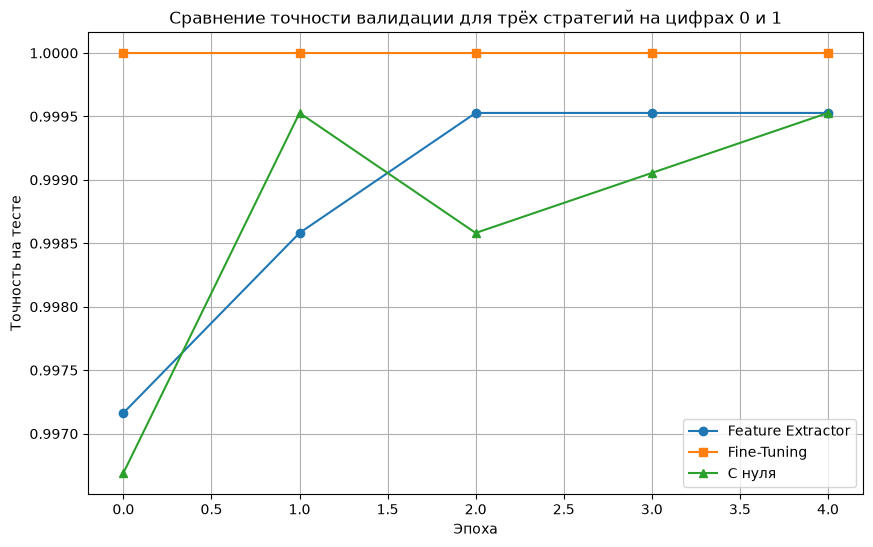

In [13]:
plt.figure(figsize=(10,6))
plt.plot(history_fe['test_acc'], label='Feature Extractor', marker='o')
plt.plot(history_ft['test_acc'], label='Fine-Tuning', marker='s')
plt.plot(history_scratch['test_acc'], label='С нуля', marker='^')
plt.xlabel('Эпоха')
plt.ylabel('Точность на тесте')
plt.title('Сравнение точности валидации для трёх стратегий на цифрах 0 и 1')
plt.legend()
plt.grid(True)
plt.show()

**Выводы по цифрам 0 и 1.** Использованы все 12 665 обучающих и 2 115 тестовых изображений, вход 224×224, по 5 эпох на этап.

| стратегия | лучшая точность на тесте | ошибок из 2 115 | время | обучаемых параметров |
|---|---|---|---|---|
| Feature Extractor (только `fc`) | 0,9995 | 1 | 107 с | 1 026 |
| Fine-Tuning (старт после FE) | **1,0000** | 0 | 214 с | 11,2 млн |
| С нуля | 0,9995 | 1 | 214 с | 11,2 млн |

- **Задача слишком простая, чтобы различить стратегии.** Как и сказано в задании, точность почти сразу равна 1. Feature Extractor с третьей эпохи ошибается на одном изображении из 2 115. Fine-Tuning даёт 1,0000 с первой эпохи. Сеть, обученная с нуля, тоже ошибается на одном изображении. Разница между стратегиями — одна картинка, то есть никакой.
- **Почему так.** 0 и 1 различаются самыми грубыми признаками: замкнутый контур против прямой черты. Такие признаки ResNet-18 легко выучивает и сама, за 1–2 эпохи на 12 тыс. изображений. Перенос обучения здесь не нужен, хотя и не мешает: признаки ImageNet, выученные на фотографиях, почти линейно разделяют рукописные 0 и 1.
- **Время.** Feature Extractor вдвое быстрее (107 с против 214 с): градиенты считаются только для последнего слоя, и обратный проход не идёт через всю сеть.
- **Оговорки к коду заготовки:**
  - лучшая эпоха выбирается по точности на тесте, поэтому числа немного оптимистичны (по-хорошему нужна отдельная валидационная выборка);
  - Fine-Tuning стартует с весов после Feature Extractor, то есть новый слой учится в сумме 10 эпох, а сеть с нуля — 5;
  - при `model.train()` слои BatchNorm даже в «замороженной» сети пересчитывают средние под новые данные, так что Feature Extractor заморожен не полностью;
  - точность на обучении (0,997) ниже, чем на тесте (0,9995): при обучении картинки случайно отражаются, а BatchNorm считает статистики по батчу, на тесте этого нет.

Различия между стратегиями видны только на более сложном наборе — см. раздел 12.

## 11. Выводы

- **Feature Extractor** (обучение только классификатора) уже даёт неплохое качество (~99%+) благодаря мощным низкоуровневым признакам, выученным на ImageNet (края, текстуры), которые оказались полезны даже для распознавания рукописных цифр — задачи, совершенно отсутствующей в ImageNet.
- **Fine-Tuning** (дообучение всех слоёв) позволяет дополнительно улучшить результат (часто до 100%), адаптируя предобученные признаки под специфику цифр.
- **Обучение с нуля** на этом же датасете также даёт высокую точность, но требует больше эпох и данных; Transfer Learning позволяет достичь отличных результатов быстрее и с меньшими вычислительными затратами.

Таким образом, Transfer Learning остаётся мощным инструментом даже когда новый домен сильно отличается от исходного, благодаря универсальности ранних слоёв нейросети.

## 12. Задача: более сложный набор данных — CIFAR-100

По заданию (на цифрах 0 и 1 точность почти сразу равна 1) повторим опыт на **CIFAR-100**: 100 классов цветных фотографий 32×32 (животные, растения, транспорт, предметы, …), по 500 обучающих и 100 тестовых изображений на класс. Многие из этих объектов есть и в ImageNet, но картинки в 7 раз меньше по стороне, а классов в 10 раз больше, чем в CIFAR-10, и среди них много похожих (клён, дуб, ива, сосна; хомяк, мышь, землеройка). Классы объединены в 20 надклассов по 5 классов («деревья», «мелкие млекопитающие», …) — это пригодится при разборе ошибок.

Условия для всех стратегий одинаковые и такие же, как для цифр: увеличение до 224×224, нормировка ImageNet, по 5 эпох, Adam, батч 32. Используется весь набор: 50 000 обучающих и 10 000 тестовых изображений. Сравниваются четыре стратегии: feature extractor, fine-tuning всей сети, fine-tuning с отдельной скоростью обучения для `layer4.1` (задание из раздела 6) и обучение с нуля.

In [14]:
from torchvision.models.resnet import ResNet18_Weights

def pretrained_resnet18():
    return models.resnet18(weights=ResNet18_Weights.DEFAULT)

cifar_train_tf = transforms.Compose([transforms.Resize(224), transforms.RandomHorizontalFlip(), transforms.ToTensor(),
                                     transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])])
cifar_val_tf = transforms.Compose([transforms.Resize(224), transforms.ToTensor(),
                                   transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])])
c_train_full = datasets.CIFAR100(DATA, train=True, download=True, transform=cifar_train_tf)
c_test_full = datasets.CIFAR100(DATA, train=False, download=True, transform=cifar_val_tf)
cifar_classes = c_train_full.classes
N_CLS = len(cifar_classes)                          # 100 классов

# весь набор: 50 000 обучающих и 10 000 тестовых изображений (в быстрой проверке — по 2 на класс и 200 тестовых)
if SMOKE:
    rng = np.random.default_rng(0)
    ytr = np.array(c_train_full.targets)
    c_tr_idx = np.concatenate([rng.choice(np.flatnonzero(ytr == c), 2, replace=False) for c in range(N_CLS)]).tolist()
    c_te_idx = list(range(200))
else:
    c_tr_idx = list(range(len(c_train_full)))
    c_te_idx = list(range(len(c_test_full)))
c_train_loader = DataLoader(Subset(c_train_full, c_tr_idx), batch_size=32, shuffle=True, num_workers=0)
c_test_loader = DataLoader(Subset(c_test_full, c_te_idx), batch_size=64, shuffle=False, num_workers=0)
print(f'CIFAR-100: классов {N_CLS}, обучение {len(c_tr_idx)}, тест {len(c_te_idx)}')

EPOCHS_C = S(5, 1)
cifar_hist = {}

# 1) Feature extractor: учим только новый fc
set_seed(42)
model_c = pretrained_resnet18()
for p in model_c.parameters():
    p.requires_grad = False
model_c.fc = nn.Linear(model_c.fc.in_features, N_CLS)
model_c = model_c.to(device)
model_c, cifar_hist['Feature Extractor'] = train_model(model_c, c_train_loader, c_test_loader, criterion,
                                                       optim.Adam(model_c.fc.parameters(), lr=1e-3), epochs=EPOCHS_C)
fe_state = copy.deepcopy(model_c.state_dict())      # от этой точки стартуют оба варианта дообучения
cifar_models = {'Feature Extractor': copy.deepcopy(model_c)}

CIFAR-100: классов 100, обучение 50000, тест 10000

Эпоха 1/5


Train Loss: 2.2795 Acc: 0.4308
Test Loss: 1.6788 Acc: 0.5466

Эпоха 2/5


Train Loss: 1.6415 Acc: 0.5503
Test Loss: 1.6007 Acc: 0.5635

Эпоха 3/5


Train Loss: 1.5387 Acc: 0.5759
Test Loss: 1.5754 Acc: 0.5732

Эпоха 4/5


Train Loss: 1.4984 Acc: 0.5848
Test Loss: 1.5731 Acc: 0.5653

Эпоха 5/5


Train Loss: 1.4558 Acc: 0.5954
Test Loss: 1.5676 Acc: 0.5754

Лучшая точность на тесте: 0.5754  (время 408 с)


In [15]:
# 2) Fine-tuning всей сети (как в разделе 6): база lr = 1e-5, классификатор lr = 1e-3
for p in model_c.parameters():
    p.requires_grad = True
base_params = [p for name, p in model_c.named_parameters() if 'fc' not in name]
opt_ft = optim.Adam([{'params': base_params, 'lr': 1e-5}, {'params': model_c.fc.parameters(), 'lr': 1e-3}])
model_c, cifar_hist['Fine-Tuning'] = train_model(model_c, c_train_loader, c_test_loader, criterion, opt_ft, epochs=EPOCHS_C)
cifar_models['Fine-Tuning'] = model_c


Эпоха 1/5


Train Loss: 1.1238 Acc: 0.6751
Test Loss: 1.0065 Acc: 0.7071

Эпоха 2/5


Train Loss: 0.8193 Acc: 0.7540
Test Loss: 0.9325 Acc: 0.7343

Эпоха 3/5


Train Loss: 0.6589 Acc: 0.7962
Test Loss: 0.9019 Acc: 0.7478

Эпоха 4/5


Train Loss: 0.5476 Acc: 0.8259
Test Loss: 0.8664 Acc: 0.7579

Эпоха 5/5


Train Loss: 0.4433 Acc: 0.8579
Test Loss: 0.8894 Acc: 0.7595

Лучшая точность на тесте: 0.7595  (время 834 с)


In [16]:
# 3) Fine-tuning с отдельной скоростью для layer4.1 (задание): база 1e-5, layer4.1 1e-4, fc 1e-3; старт — та же точка после FE
set_seed(42)
model_l4 = pretrained_resnet18()
model_l4.fc = nn.Linear(model_l4.fc.in_features, N_CLS)
model_l4.load_state_dict(fe_state)
model_l4 = model_l4.to(device)
model_l4, cifar_hist['FT, layer4.1 lr=1e-4'] = train_model(model_l4, c_train_loader, c_test_loader, criterion,
                                                           layerwise_optimizer(model_l4), epochs=EPOCHS_C)
cifar_models['FT, layer4.1 lr=1e-4'] = model_l4


Эпоха 1/5


Train Loss: 1.1729 Acc: 0.6645
Test Loss: 0.9802 Acc: 0.7135

Эпоха 2/5


Train Loss: 0.7558 Acc: 0.7684
Test Loss: 0.9434 Acc: 0.7338

Эпоха 3/5


Train Loss: 0.5551 Acc: 0.8288
Test Loss: 0.8904 Acc: 0.7558

Эпоха 4/5


Train Loss: 0.4155 Acc: 0.8676
Test Loss: 0.9721 Acc: 0.7528

Эпоха 5/5


Train Loss: 0.3150 Acc: 0.8986
Test Loss: 0.9861 Acc: 0.7534

Лучшая точность на тесте: 0.7558  (время 825 с)


In [17]:
# 4) Та же ResNet-18 со случайной инициализацией (с нуля), всё как в разделе 9
set_seed(42)
model_cs = models.resnet18(weights=None, num_classes=N_CLS).to(device)
model_cs, cifar_hist['С нуля'] = train_model(model_cs, c_train_loader, c_test_loader, criterion,
                                             optim.Adam(model_cs.parameters(), lr=1e-3), epochs=EPOCHS_C)
cifar_models['С нуля'] = model_cs


Эпоха 1/5


Train Loss: 3.8635 Acc: 0.1027
Test Loss: 3.3336 Acc: 0.1905

Эпоха 2/5


Train Loss: 3.0582 Acc: 0.2381
Test Loss: 2.6950 Acc: 0.3059

Эпоха 3/5


Train Loss: 2.4014 Acc: 0.3689
Test Loss: 2.1409 Acc: 0.4264

Эпоха 4/5


Train Loss: 1.9590 Acc: 0.4674
Test Loss: 1.8897 Acc: 0.4796

Эпоха 5/5


Train Loss: 1.6513 Acc: 0.5390
Test Loss: 1.6400 Acc: 0.5438

Лучшая точность на тесте: 0.5438  (время 847 с)


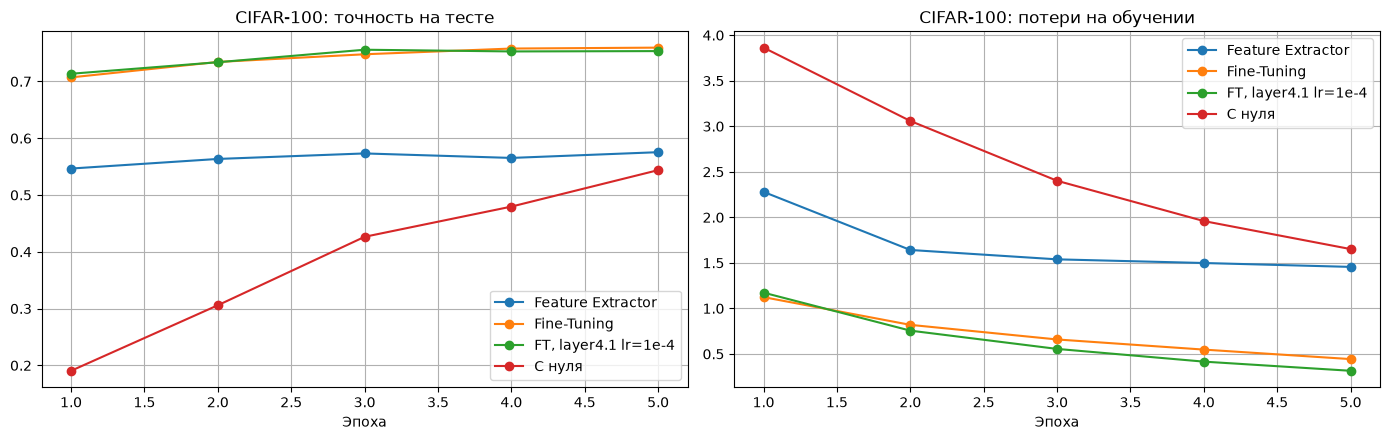

стратегия                лучшая точность  время, с  обучаемых параметров
Feature Extractor                 0.5754       408                51,300
Fine-Tuning                       0.7595       834            11,227,812
FT, layer4.1 lr=1e-4              0.7558       825            11,227,812
С нуля                            0.5438       847            11,227,812


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for name, h in cifar_hist.items():
    e = range(1, len(h['test_acc']) + 1)
    axes[0].plot(e, h['test_acc'], 'o-', label=name)
    axes[1].plot(e, h['train_loss'], 'o-', label=name)
axes[0].set_title('CIFAR-100: точность на тесте'); axes[1].set_title('CIFAR-100: потери на обучении')
for ax in axes:
    ax.set_xlabel('Эпоха'); ax.grid(True); ax.legend()
plt.tight_layout(); plt.show()

print(f"{'стратегия':<24}{'лучшая точность':>16}{'время, с':>10}{'обучаемых параметров':>22}")
n_params = {'Feature Extractor': 512 * N_CLS + N_CLS, 'Fine-Tuning': sum(p.numel() for p in model_c.parameters()),
            'FT, layer4.1 lr=1e-4': sum(p.numel() for p in model_l4.parameters()), 'С нуля': sum(p.numel() for p in model_cs.parameters())}
for name, h in cifar_hist.items():
    print(f"{name:<24}{max(h['test_acc']):>16.4f}{h['time']:>10.0f}{n_params[name]:>22,}")

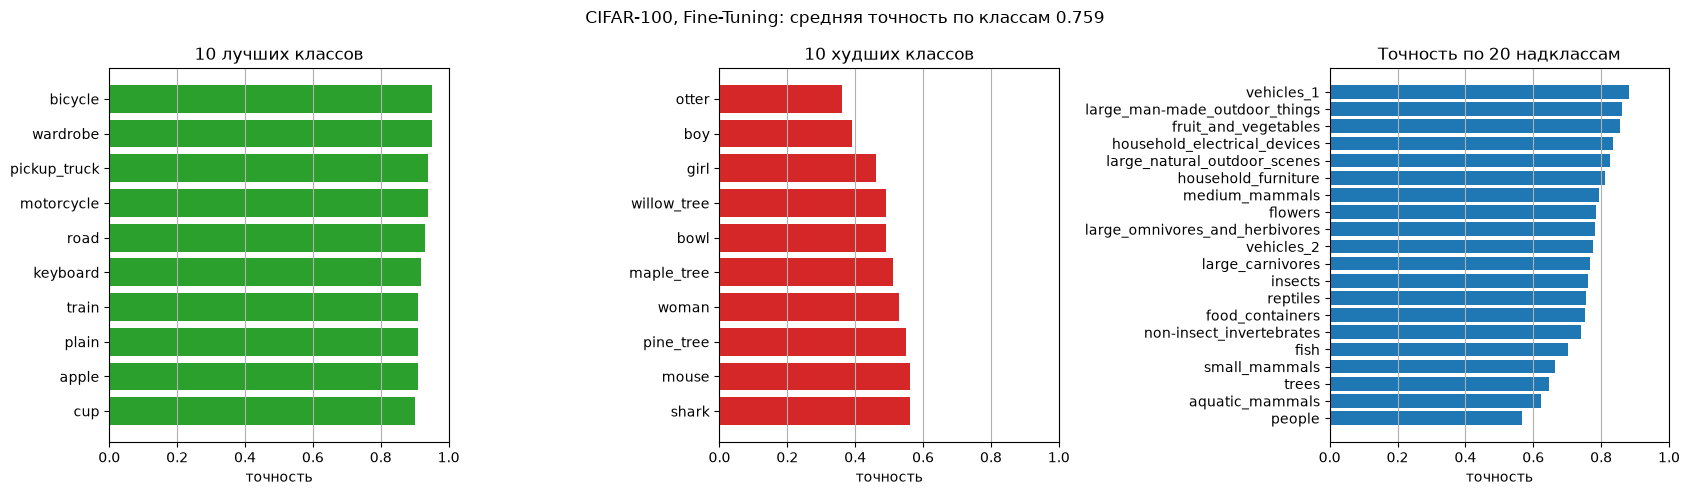

ошибок: 2405 из 10000; надкласс угадан в 41.7% ошибок (при случайной ошибке было бы 4.0%: в надклассе ещё 4 класса из 99 оставшихся)
точность по надклассам (20 классов вместо 100): 0.860
самые частые путаницы (истинный -> предсказанный: число ошибок из 100 тестовых изображений класса):
      maple_tree -> oak_tree        29   надкласс: тот же (trees)
             boy -> girl            22   надкласс: тот же (people)
       streetcar -> train           22   надкласс: разные
       pine_tree -> oak_tree        21   надкласс: тот же (trees)
           otter -> seal            21   надкласс: тот же (aquatic_mammals)
     willow_tree -> oak_tree        20   надкласс: тот же (trees)
            girl -> woman           19   надкласс: тот же (people)
             boy -> man             19   надкласс: тот же (people)
           woman -> girl            17   надкласс: тот же (people)
            rose -> tulip           16   надкласс: тот же (flowers)
            girl -> baby            15   надк

In [19]:
# Ошибки лучшей модели на CIFAR-100: точность по классам и надклассам, частые путаницы
import collections
import pickle

best_c_name = max(cifar_hist, key=lambda n: max(cifar_hist[n]['test_acc']))
best_c = cifar_models[best_c_name]
best_c.eval()
preds, ys = [], []
with torch.no_grad():
    for x, y in c_test_loader:
        preds.append(best_c(x.to(device)).argmax(1).cpu()); ys.append(y)
preds, ys = torch.cat(preds).numpy(), torch.cat(ys).numpy()

# надклассы (coarse labels) есть в исходных файлах набора, torchvision их не загружает
c100_dir = os.path.join(DATA, 'cifar-100-python')
with open(os.path.join(c100_dir, 'test'), 'rb') as f:
    coarse_all = np.array(pickle.load(f, encoding='latin1')['coarse_labels'])
with open(os.path.join(c100_dir, 'meta'), 'rb') as f:
    coarse_names = pickle.load(f, encoding='latin1')['coarse_label_names']
fine2coarse = dict(zip(np.array(c_test_full.targets).tolist(), coarse_all.tolist()))
ys_coarse = np.array([fine2coarse[t] for t in ys])
preds_coarse = np.array([fine2coarse[p] for p in preds])

acc_cls = np.array([(preds[ys == c] == c).mean() if (ys == c).any() else np.nan for c in range(N_CLS)])
valid = [c for c in np.argsort(acc_cls) if not np.isnan(acc_cls[c])]
worst, best = valid[:10], valid[-10:][::-1]
acc_sup = np.array([(preds[ys_coarse == k] == ys[ys_coarse == k]).mean() if (ys_coarse == k).any() else np.nan
                    for k in range(len(coarse_names))])
order_sup = [k for k in np.argsort(acc_sup) if not np.isnan(acc_sup[k])]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
axes[0].barh([cifar_classes[i] for i in best][::-1], acc_cls[best][::-1], color='C2'); axes[0].set_title('10 лучших классов')
axes[1].barh([cifar_classes[i] for i in worst][::-1], acc_cls[worst][::-1], color='C3'); axes[1].set_title('10 худших классов')
axes[2].barh([coarse_names[k] for k in order_sup], acc_sup[order_sup], color='C0'); axes[2].set_title('Точность по 20 надклассам')
for ax in axes:
    ax.set_xlim(0, 1); ax.set_xlabel('точность'); ax.grid(True, axis='x')
plt.suptitle(f'CIFAR-100, {best_c_name}: средняя точность по классам {np.nanmean(acc_cls):.3f}')
plt.tight_layout(); plt.show()

wrong = preds != ys
same_super = (preds_coarse[wrong] == ys_coarse[wrong]).mean() if wrong.any() else float('nan')
print(f'ошибок: {wrong.sum()} из {len(ys)}; надкласс угадан в {same_super:.1%} ошибок '
      f'(при случайной ошибке было бы {4 / 99:.1%}: в надклассе ещё 4 класса из 99 оставшихся)')
print(f'точность по надклассам (20 классов вместо 100): {(preds_coarse == ys_coarse).mean():.3f}')
print('самые частые путаницы (истинный -> предсказанный: число ошибок из 100 тестовых изображений класса):')
for (t, p), n in collections.Counter(zip(ys[wrong].tolist(), preds[wrong].tolist())).most_common(12):
    print(f'  {cifar_classes[t]:>14s} -> {cifar_classes[p]:<14s} {n:3d}   надкласс: '
          f'{"тот же (" + coarse_names[fine2coarse[t]] + ")" if fine2coarse[t] == fine2coarse[p] else "разные"}')


**Выводы по CIFAR-100.** Весь набор: 50 000 обучающих и 10 000 тестовых изображений, 100 классов, вход 224×224, по 5 эпох.

| стратегия | точность по эпохам | лучшая точность | время | обучаемых параметров |
|---|---|---|---|---|
| Feature Extractor | 0,547 → 0,564 → 0,573 → 0,565 → 0,575 | 0,575 | 408 с | 51 300 |
| **Fine-Tuning** (старт после FE) | 0,707 → 0,734 → 0,748 → 0,758 → 0,760 | **0,760** | 834 с | 11,2 млн |
| Fine-Tuning, `layer4.1` с lr = 1e-4 | 0,714 → 0,734 → 0,756 → 0,753 → 0,753 | 0,756 | 825 с | 11,2 млн |
| С нуля | 0,191 → 0,306 → 0,426 → 0,480 → 0,544 | 0,544 | 847 с | 11,2 млн |

- **Здесь перенос обучения выигрывает отчётливо.** Дообученная сеть точнее сети, обученной с нуля, на 21,6 п. п. (0,760 против 0,544). Даже один линейный слой поверх замороженных признаков ImageNet (0,575) точнее сети с нуля, хотя обучается вдвое быстрее (408 с против 847 с) и имеет в 220 раз меньше обучаемых параметров.
- **Честное сравнение по времени.** Fine-Tuning начинается после Feature Extractor, поэтому в сумме это 1 242 с против 847 с у сети с нуля. Но уже после первой эпохи дообучения (около 575 с вместе с FE) точность 0,707 — намного выше итоговых 0,544 сети с нуля.
- **Feature Extractor быстро упирается в потолок:** 0,55–0,58 уже со второй эпохи, train loss почти не падает (1,64 → 1,46). Признаки ImageNet для картинок 32×32, растянутых до 224, подходят лишь частично. Их нужно подстроить, что и делает дообучение: +18,4 п. п.
- **Сеть с нуля не обучилась до конца:** точность растёт на 5–12 п. п. за эпоху, test loss продолжает падать. За 5 эпох ей просто не хватило времени. Перенос обучения даёт хорошее качество быстро.
- **Отдельная скорость для `layer4.1`** (1e-4 вместо 1e-5): последний блок действительно адаптируется быстрее. На 3-й эпохе 0,756 против 0,748 у обычного дообучения, train loss ниже. Но дальше модель переобучается: test loss растёт с 0,89 до 0,99, а точность на обучении доходит до 0,90 при 0,75 на тесте. Итог — 0,756 против 0,760, разница 0,4 п. п. в пределах шума одного запуска. Ускорение есть, выигрыша в качестве нет; с такой скоростью для `layer4.1` нужна ранняя остановка или меньше эпох.
- **Переобучение есть и у обычного дообучения:** точность на обучении 0,86 против 0,76 на тесте, минимум test loss — на 4-й эпохе (0,866).

**Где ошибается лучшая модель** (Fine-Tuning, 2 405 ошибок из 10 000):
- **Ошибки в основном «разумные».** В 41,7 % ошибок модель угадывает надкласс, хотя при случайной ошибке это было бы 4 %. Если считать точность по 20 надклассам, она равна 0,860 вместо 0,760 по 100 классам.
- **Самые частые путаницы — внутри надкласса:**
  - деревья: клён → дуб (29 из 100), сосна → дуб (21), ива → дуб (20);
  - люди: мальчик → девочка (22), девочка → женщина (19), мальчик → мужчина (19), женщина → девочка (17), девочка → младенец (15);
  - морские млекопитающие: выдра → тюлень (21), дельфин → кит (14);
  - цветы: роза → тюльпан (16).
- **Среди 12 самых частых путаниц** только одна — между разными надклассами: трамвай → поезд (22). По смыслу это тоже близкие классы.
- **Лучше всего распознаются** транспорт и предметы с чёткой формой: велосипед, шкаф, пикап, мотоцикл, дорога, клавиатура (около 0,9–0,95).
- **Хуже всего** — выдра (около 0,36), мальчик (0,39), девочка (0,46), ива, миска, клён (около 0,5).
- **По надклассам:** лучше всего «транспорт 1» (около 0,88), хуже всего «люди» (около 0,57), «морские млекопитающие», «деревья» и «мелкие млекопитающие» (0,62–0,66).
- **Почему именно эти классы.** Классы с людьми различаются возрастом и полом, а на картинке 32×32 таких деталей почти не видно; в ImageNet-1k нет классов вроде «мальчик» или «женщина», поэтому готовых признаков для них сеть не принесла. Деревья и морские млекопитающие при таком разрешении, по-видимому, тоже различаются в основном цветом и фоном.

**Заключение:**
1. Увеличилась ли эффективность модели за теже самые вычислительные ресурсы?
2. Новые навыки/умения/знания.
3. Пожелания по наполнению лекции и практики.

1. **Увеличилась ли эффективность за те же ресурсы?**
   - **На CIFAR-100 — да, и сильно.** За то же время, что сеть с нуля (около 830–850 с), дообученная сеть даёт 0,760 вместо 0,544. Feature Extractor за вдвое меньшее время (408 с) даёт 0,575 — тоже больше, чем сеть с нуля.
   - **На цифрах 0 и 1 — нет.** Все три стратегии дают 0,9995–1,0000, задача решается и без переноса.
2. **Новые навыки и знания.**
   - Замораживание слоёв через `requires_grad`; разные скорости обучения для групп параметров (`layer4.1`, `fc`, остальные слои).
   - Понимание, что BatchNorm в режиме `train()` меняет статистики и в «замороженной» сети.
   - Отбор классов по массиву меток вместо прохода по набору с преобразованиями — в 11 тыс. раз быстрее.
   - Разбор ошибок по надклассам CIFAR-100 (их метки есть в исходных файлах набора): так видно, что большая часть ошибок — путаница близких классов.
3. **Пожелания.**
   - Сразу дать более сложный набор, например CIFAR-100: на цифрах 0 и 1 стратегии не различаются.
   - Выбирать лучшую эпоху по валидационной выборке, а не по тесту.
   - Оговорить, что Fine-Tuning продолжает обучение после Feature Extractor: иначе сравнение с обучением с нуля выглядит неравным.
   - Указать ожидаемое время. На Mac с Apple Silicon вся тетрадка с CIFAR-100 заняла 75 мин, из них около 58 мин — обучение.